In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

# Dark

## Momentum

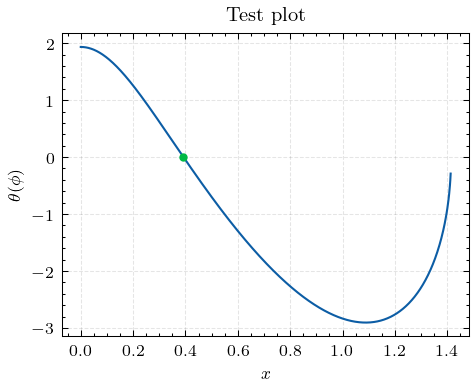

In [2]:
cs = np.linspace(0, np.sqrt(2), 1000, endpoint=False)
c_0 = np.sqrt(2)/2
k = -10
P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

plt.plot(cs, P_p(cs, k), marker="none")
plt.plot(c_star, P_p_(c_star), ".")
plt.title("Test plot")
plt.xlabel("$x$")
plt.ylabel(r"$\theta(\phi)$")
plt.show()

/Users/sebastian/Desktop/Phd/Nonlinear-Schrodinger/Tests and Results/QGP/DS_Stability/../../../Utilities.py:141: RuntimeWarning: divide by zero encountered in scalar divide
  frac = (3 * c**2 * k - 4 * k - 1)/(4 * np.sqrt(-k))
/Users/sebastian/Desktop/Phd/Nonlinear-Schrodinger/Tests and Results/QGP/DS_Stability/../../../Utilities.py:143: RuntimeWarning: invalid value encountered in scalar multiply
  sum_1 = frac * np.arctanh(np.sqrt(-k)/sqrt)
/Users/sebastian/Desktop/Phd/Nonlinear-Schrodinger/Tests and Results/QGP/DS_Stability/../../../Utilities.py:140: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt((1 - 2 * k)/(2 - c**2))
/Users/sebastian/Desktop/Phd/Nonlinear-Schrodinger/Tests and Results/QGP/DS_Stability/../../../Utilities.py:152: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt((1 - 2 * k)/(2 - c**2))


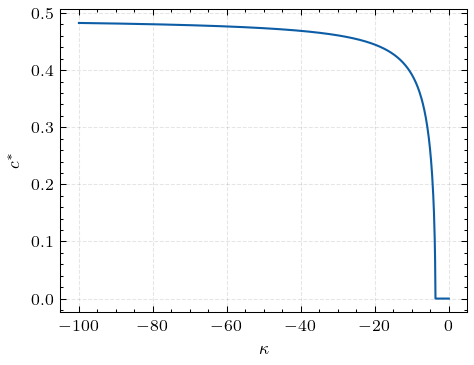

In [3]:
ks = -np.linspace(0, 100, 1_000)
c_0 = np.sqrt(2)/2
c_stars = np.zeros(len(ks))

for j in range(len(ks)):
    k = ks[j]
    P_p_ = lambda c: P_p(c, k)
    P_pp_ = lambda c: P_pp(c, k)

    c_star, error = newton_1D(c_0, P_p_, P_pp_)
    c_stars[j] = c_star

plt.plot(ks, c_stars, marker="none")
plt.xlabel(r"$\kappa$")
plt.ylabel(r"$c^*$")
#plt.savefig("k_vs_c_star.pdf", dpi=300, bbox_inches = "tight")
plt.show()
#plt.ylim(0, 0.55)

## Finding A's

In [4]:
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)
print("c* = ", c_star)

eps = 0.1
c_in = c_star - eps

c* =  0.4734813690779277


In [5]:
def G_c_k(A, c, k, get_roots=False):

    d2eta_zero = (c**2 - c**4 - 1)/(1 - k * c**2)
    d2rho_zero = -(np.sqrt(2) / (2 * c)) * d2eta_zero
    const_1 = - (np.sqrt(2) * c * ((2 - c**2) / (2 * c))**2 + 2 * np.sqrt(2) * c - 2 * d2rho_zero)
    const_2 = d2rho_zero * np.sqrt(2) * c

    output = -4*A**2 + const_1 * A + const_2

    if get_roots:
        coeffs = [-4, const_1, const_2]
        roots = np.roots(coeffs)
        return output, roots

    return output

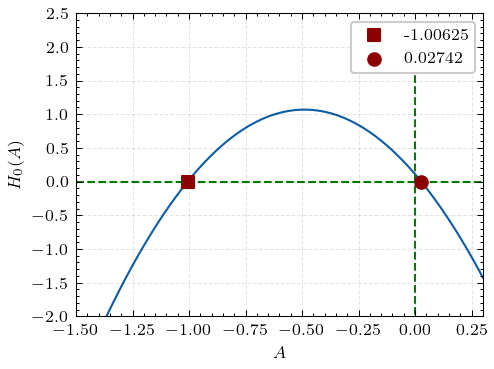

In [6]:
A = np.linspace(-3, 0.5, 10_000)
G_c_k_plot, roots = G_c_k(A, c_in, k, get_roots=True)
plt.plot(A, G_c_k_plot, "-", zorder=0)
plt.hlines(0, A[0], A[-1], ls="--", color="green", zorder=0)
plt.vlines(0, -4, 2, ls="--", color="green", zorder=0)
plt.scatter(roots[0], 0, label=round(roots[0], 5), marker="s", color="darkred")
plt.scatter(roots[1], 0, label=round(roots[1], 5), color="darkred")
#plt.xlim(-0.01, 0.1)
#plt.ylim(-0.5, 0.5)
plt.xlim(-1.5, 0.3)
plt.ylim(-2., 2.5)
plt.xlabel(r"$A$")
plt.ylabel(r"$H_0(A)$")
plt.legend()
plt.show()

## Simulation

In [2]:
k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)
print("c* = ", c_star)

eps = 0.1
c_un = c_star - eps

c* =  0.4734813690779277


In [3]:
L = 400
N = 10_001
Nt = 10_000 #10_000
tf = 5 #1 #15

w_dark_un, x_dark_un = soliton(c_un, k, soliton_type="dark", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [22]:
w_un = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_un.set_init_condition(w_dark_un)
w_un.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  3.507586306746216e-14 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  3.76710837042204e-14 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  3.7278951281312595e-14 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  3.6747591495266484e-14 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  3.665711490984067e-14 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  3.780432505987742e-14 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  3.7930768898816834e-14 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  3.49590036161699e-14 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  3.7428088989481355e-14 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  3.597893905331489e-14 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  3.349417137453409e-14 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  3.745336985087375e-

In [4]:
def theo_dark_un(x, t):
    output = w_dark_un(x - c_un*t)
    return output

In [5]:
def g(x, A):
    return A * np.exp(-x**2)

def g_1(x, A):
    return -2 * A * x * np.exp(-x**2)

def g_2(x, A):
    return -2 * A * np.exp(-x**2) + 4 * A * x**2 * np.exp(-x**2)


In [8]:
np.random.seed(67)

def sol_gauss(x, A):
    output = w_dark_un(x) + g(x, A) #A*np.exp(-x**2)
    return output

eps_rand = 1e-1
A_rand = np.random.rand(len(x_dark_un)) * eps_rand
A_rand[np.abs(x_dark_un)>=L/2] = eps_rand
#A = #2e-2 #1e-2#0.02041595129863531 #7e-2#roots[1]-0.02
#sigma=10
init_cond = lambda x: sol_gauss(x, A_rand)

(-10.0, 10.0)

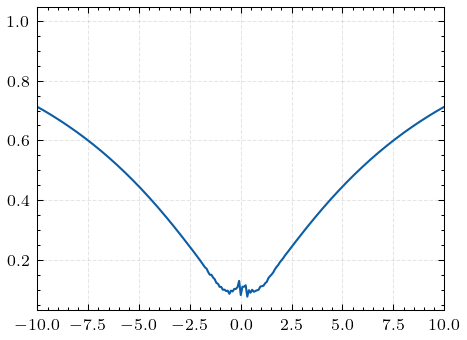

In [11]:
plt.plot(x_dark_un, norm(init_cond(x_dark_un)), marker="none", ls="-")
plt.xlim(-10, 10)

In [12]:
w_un_gauss_rand = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_un_gauss_rand.set_init_condition(init_cond)
w_un_gauss_rand.solve(b_tol=1e-4)#method="fixed point")

Iteration  1  of  10000 . Newton Error:  3.611256099363012e-14 . Total iteration:  4
Iteration  2  of  10000 . Newton Error:  2.8181276624350045e-11 . Total iteration:  3
Iteration  3  of  10000 . Newton Error:  1.748692080299506e-11 . Total iteration:  3
Iteration  4  of  10000 . Newton Error:  1.824229130721214e-11 . Total iteration:  3
Iteration  5  of  10000 . Newton Error:  8.639303362405346e-11 . Total iteration:  3
Iteration  6  of  10000 . Newton Error:  4.686064847715923e-11 . Total iteration:  3
Iteration  7  of  10000 . Newton Error:  6.650873304952503e-11 . Total iteration:  3
Iteration  8  of  10000 . Newton Error:  3.429426899954753e-14 . Total iteration:  4
Iteration  9  of  10000 . Newton Error:  8.360461012487175e-12 . Total iteration:  3
Iteration  10  of  10000 . Newton Error:  2.2927068384608672e-11 . Total iteration:  3
Iteration  11  of  10000 . Newton Error:  3.038602289287593e-11 . Total iteration:  3
Iteration  12  of  10000 . Newton Error:  1.4208020736141201e

KeyboardInterrupt: 

(-25.0, 25.0)

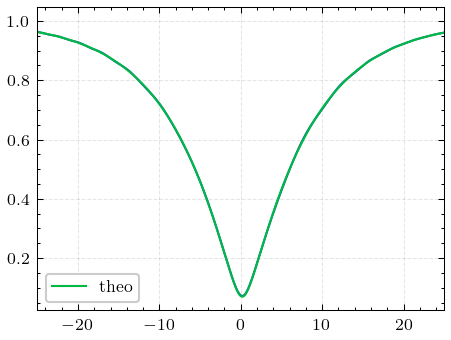

In [59]:
j = 5000
plt.plot(w_in_gauss_01.x, norm(w_in_gauss_01.w[j]), marker="none", ls="-")
plt.plot(w_in_gauss_01.x, norm(theo_dark_in(w_in_gauss_01.x, w_in_gauss_01.t[j])),
         marker="none", ls="-", label="theo")
#plt.plot(w_in.x, norm(w_in.w[j]))
#plt.xlim(-1, 1)
#plt.ylim(0, 0.8)
plt.legend()
plt.xlim(-25, 25)

In [27]:
#w_in.w_theo = theo_dark_in
w_un_gauss_rand.w_theo = theo_dark_un
#w_in_gauss_001.w_theo = theo_dark_in
#w_in_gauss_0001.w_theo = theo_dark_in
#w_in_gauss_00001.w_theo = theo_dark_in

#L2_errors = w_in.get_error()#np.zeros(len(w_in.w)-1)
L2_errors_gauss_rand = w_un_gauss_rand.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_001 = w_in_gauss_001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_0001 = w_in_gauss_0001.get_error()#np.zeros(len(w_in.w)-1)
#errors_gauss_00001 = w_in_gauss_00001.get_error()#np.zeros(len(w_in.w)-1)


In [28]:
i = 1j

def inner(x, y):
    return np.real(np.conjugate(x) * y)

def integrand(x, A, k, c=c_un):
    h = x[1] - x[0]
    u = w_dark_in(x)
    u_1 = np.gradient(u, h)
    u_2 = np.gradient(u_prime, h)
    
    g_ = g(x, A)
    g_1_ = g_1(x, A)
    g_2_ = g_2(x, A)

    output_1 = inner(u, i*(g_*(1-norm(u + g_)) -g_2_) - c*g_1_)
    output_2 = k * inner(u_2*g_+2*u_1*g_1_+u*g_2_, i*(norm(u) + g_**2 + u*g_))
    return output_1 + output_2

def m_t_0(x, A, k):
    J = x.size
    h = x[1] - x[0]
    integrand_ = integrand(x, A, k)
    integ = h/2 * (integrand_[0] + integrand_[1])
    
    for j in range(J-1):
        integ = integ + (h/2 * (integrand_[j] + integrand_[j+1]))

    return 2*integ

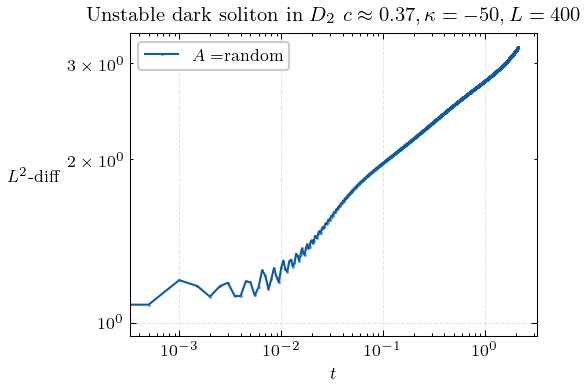

In [32]:
ms = .5
#m_0 = A * (np.pi/2)**(1/4)

cond = norm(w_un_gauss_rand.w) != 0
norm_g = np.sqrt(w_un_gauss_rand.h) * np.linalg.norm(g(x_dark_un, A_rand), ord=2)

#plt.plot(0, m_0**2, ms=2)
#plt.axline((0, m_0**2), slope=slope, linewidth=1)
#plt.plot(w_in.t, L2_errors**2, ".", label="Standard", ms=ms)
plt.plot(w_un_gauss_rand.t[cond[:, 0]], L2_errors_gauss_rand[cond[:, 0]]/norm_g, ".-", label=r"$A=$random", ms=ms)
#plt.plot(w_in.t, errors_gauss_001, ".", label=r"Gauss $A=10^{-2}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_0001, ".", label=r"Gauss $A=10^{-3}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_00001, ".", label=r"Gauss $A=10^{-4}$", ms=ms)
plt.title(r"Unstable dark soliton in $D_2$ $c\approx{c}, \kappa={k}, L={L}$".format(c=round(c_un, 2), k=k, L=L))
plt.xlabel(r"$t$")
plt.ylabel(r"$L^2$-diff", rotation='horizontal', ha='right')
plt.yscale("log")
plt.xscale("log")
plt.legend()

#plt.xlim(-0.001, 0.02)
#plt.savefig("diffs/unstable_dark_D2.png", dpi=300, bbox_inches = "tight")
plt.show()

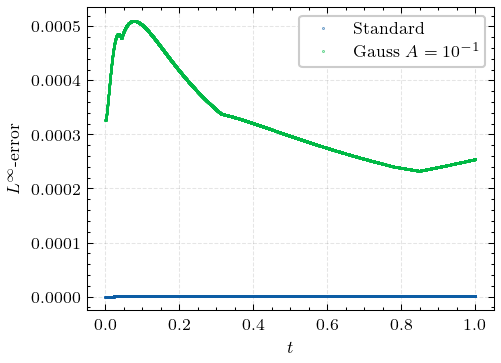

In [61]:
ms = .5
plt.plot(w_in.t, errors_inf, ".", label="Standard", ms=ms)
plt.plot(w_in.t, errors_gauss_01, ".", label=r"Gauss $A=10^{-1}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_001, ".", label=r"Gauss $A=10^{-2}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_0001_inf, ".", label=r"Gauss $A=10^{-3}$", ms=ms)
#plt.plot(w_in.t, errors_gauss_00001_inf, ".", label=r"Gauss $A=10^{-4}$", ms=ms)
plt.xlabel(r"$t$")
plt.ylabel(r"$L^\infty$-error")
#plt.yscale("log")
plt.legend()
plt.show()

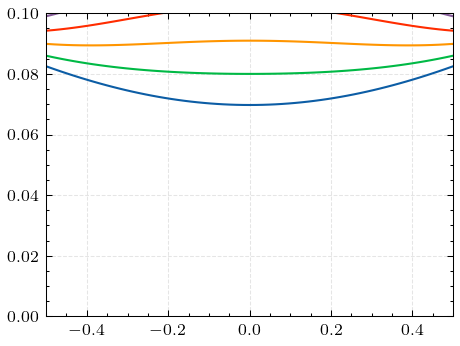

In [11]:
def sol_gauss(x, A):
    output = w_dark_in(x) + A*np.exp(-x**2)
    return output

As = np.linspace(0, 0.15, 9)#[10**(-j/5) for j in range(3, 6)]

for A in As:
    A_sci = sci_notation(A)
    plt.plot(x_dark_in, norm(sol_gauss(x_dark_in, A)), "-", label="A={}".format(A_sci))

#plt.plot(w_in.x, norm(w_in.w[0]), "-", label="A=0")
#plt.legend(fontsize=5)
plt.ylim(0, 0.1)
plt.xlim(-.5, .5)
plt.show()

# Antidark

In [2]:
# Create solitons
L = 30
N = 10_001
eps = 0.01
k = 0.501#+eps
#0.1

pars = {"k":k}

c_1 = 1 + np.sqrt(2)

# Theretical solitons
w_anti, x_anti = soliton(c_1, k, soliton_type="anti", L=L, N=N)#, as_func=True) #c=0

Creating soliton...
Soliton created


In [3]:
Nt = 10_000
tf = 2.5e-4

w_comp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_init_array(w_anti)
w_comp.solve()

Iteration  1  of  10000 . Newton Error:  1.2528058735852438e-16 . Total iteration:  1
Iteration  2  of  10000 . Newton Error:  1.336870469378737e-16 . Total iteration:  1
Iteration  3  of  10000 . Newton Error:  1.229190144648996e-16 . Total iteration:  1
Iteration  4  of  10000 . Newton Error:  1.4613210304893156e-16 . Total iteration:  1
Iteration  5  of  10000 . Newton Error:  1.2217965106888958e-16 . Total iteration:  1
Iteration  6  of  10000 . Newton Error:  1.4940733519410273e-16 . Total iteration:  1
Iteration  7  of  10000 . Newton Error:  1.228904856423343e-16 . Total iteration:  1
Iteration  8  of  10000 . Newton Error:  1.199029320748348e-16 . Total iteration:  1
Iteration  9  of  10000 . Newton Error:  1.4158182782505676e-16 . Total iteration:  1
Iteration  10  of  10000 . Newton Error:  1.2111606429587178e-16 . Total iteration:  1
Iteration  11  of  10000 . Newton Error:  1.3987001184888426e-16 . Total iteration:  1
Iteration  12  of  10000 . Newton Error:  1.332425490782

In [4]:
w_max = np.abs(w_comp.w).max(axis=1)

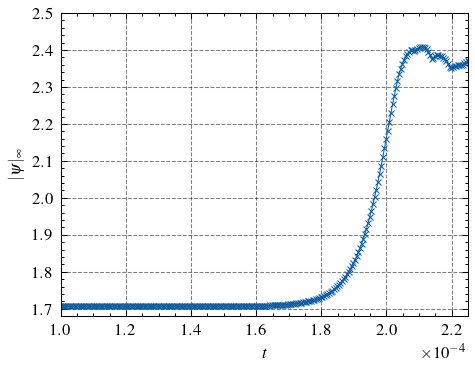

In [6]:
#j_max = 1628
indices = np.linspace(0, len(w_comp.w)-1, 500, dtype=int)
plt.plot(w_comp.t[indices], w_max[indices], "x-", lw=.5, markeredgewidth=.5, ms=3)
plt.xlim(1e-4, 2.25e-4)
plt.ylim(1.68, 2.5)

plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlabel(r"$t$")
plt.ylabel(r"$|\psi|_\infty$")
plt.savefig("Antidark/Local/infinity_norm_anti.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Antidark/Local/infinity_norm_anti.pgf", dpi=300, bbox_inches = "tight")
plt.show()

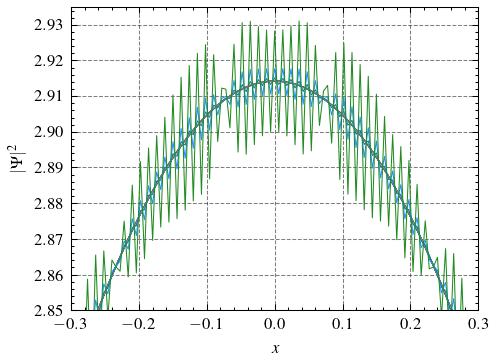

In [10]:
w_time = w_comp.t[w_comp.t<0.00017]
total_plot = len(w_time)
indices = np.linspace(0, total_plot-1, 20, dtype=int)
x_indices = np.where(np.abs(w_comp.x)<0.5)

w_plot = w_comp.w[:total_plot]
for n in indices:
    plt.plot(w_comp.x[x_indices], norm(w_plot[n][x_indices]), "-", lw=.5,
             markeredgewidth=.5, ms=5)
plt.xlim(-0.3,0.3)
plt.ylim(2.85, 2.935)
plt.ylabel(r"$|\Psi|^2$")
plt.xlabel(r"$x$")

plt.savefig("Antidark/Local/anti_evol.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Antidark/Local/anti_evol.pgf", dpi=300, bbox_inches = "tight")
plt.show()

In [11]:
e = w_comp.get_energy()

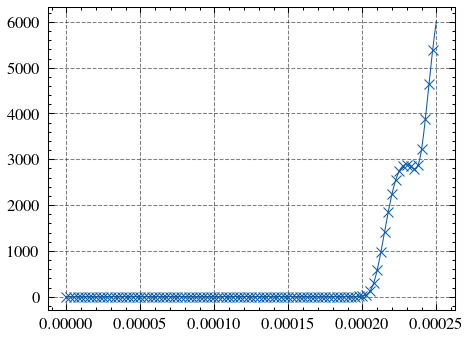

In [17]:
plt.plot(w_comp.t, e, "x-", lw=.5, markevery=100, markeredgewidth=.5, ms=5)

In [19]:
norm_grad_w = np_norm(np.gradient(w_comp.w, w_comp.h, axis=1), np.inf, axis=1)

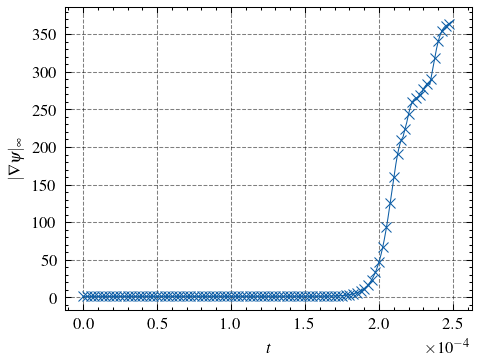

In [28]:
plt.plot(w_comp.t, norm_grad_w, "x-", lw=.5, markevery=100, markeredgewidth=.5, ms=5)
#plt.xlim(1.3e-4, 2.4e-4)
#plt.ylim(-0.1, 1.5)

plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlabel(r"$t$")
plt.ylabel(r"$|\nabla \psi|_\infty$")

#plt.yscale("log")
#plt.xscale("log", base=2)
plt.savefig("Antidark/Local/inf_grad_anti.pdf", dpi=300, bbox_inches = "tight")
plt.savefig("Antidark/Local/inf_grad_anti.pgf", dpi=300, bbox_inches = "tight")

plt.show()

In [29]:
norm_H2_w = np.sqrt(w_comp.h) * np_norm(np.gradient(w_comp.w, w_comp.h, axis=1), 2, axis=1)

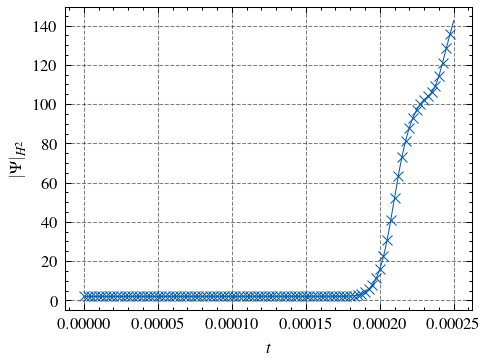

In [31]:
plt.plot(w_comp.t, norm_H2_w, "x-", lw=.5, markevery=100, markeredgewidth=.5, ms=5)
plt.ylabel(r"$|\Psi|_{H^2}$")
plt.xlabel(r"$t$")
plt.show()
#plt.xlim(1.3e-4, 2.5e-4)
#plt.ylim(1.68, 2.5)